# Artificial Compressibility for a Mixed Darcy Saddle-Point System

## 1. Understanding Artificial Compressibility

In this notebook, I will study the artificial compressibility approach for a mixed Darcy saddle-point system.

My original system is:

$$
G =
\begin{bmatrix}
A & -D^T \\
-D & 0
\end{bmatrix}
$$

The modified matrix is:

$$
\widetilde{G}_\alpha =
\begin{bmatrix}
A & -D^T \\
-D & -\alpha I
\end{bmatrix}
$$

Here, alpha is a positive artificial compressibility parameter.

I want to understand how adding a small pressure-block term changes the system.

In this first step, I will use a small matrix example to compare the original and modified systems.

The modified system is not the final Darcy problem. Later, I will study how to use it in an iterative method for solving the original system.


In [14]:
# Step 1: Small artificial compressibility example

import numpy as np

# Small flux mass matrix
A_demo = np.array([
    [2.0, 0.0],
    [0.0, 4.0]
])

# Small divergence matrix
D_demo = np.array([[1.0, 1.0]])

# Artificial compressibility parameter
alpha = 0.1

# Original saddle-point matrix
G_demo = np.block([
    [A_demo, -D_demo.T],
    [-D_demo, np.zeros((1, 1))]
])

# Modified matrix
G_modified = np.block([
    [A_demo, -D_demo.T],
    [-D_demo, -alpha * np.eye(1)]
])

# Right-hand side
b_demo = np.array([0.0, 0.0, -1.0])

# Solve both systems
z_original = np.linalg.solve(G_demo, b_demo)
z_modified = np.linalg.solve(G_modified, b_demo)

# Check both solutions against the ORIGINAL system
residual_original = np.linalg.norm(
    b_demo - G_demo @ z_original
)

residual_modified = np.linalg.norm(
    b_demo - G_demo @ z_modified
)

# Display results
print("Original matrix:")
print(G_demo)

print("\nModified matrix:")
print(G_modified)

print("\nArtificial compressibility parameter:", alpha)

print("\nOriginal solution:", z_original)
print("Modified solution:", z_modified)

print("\nOriginal system residual:", residual_original)
print("Modified solution residual in original system:",
      residual_modified)

Original matrix:
[[ 2.  0. -1.]
 [ 0.  4. -1.]
 [-1. -1.  0.]]

Modified matrix:
[[ 2.   0.  -1. ]
 [ 0.   4.  -1. ]
 [-1.  -1.  -0.1]]

Artificial compressibility parameter: 0.1

Original solution: [0.66666667 0.33333333 1.33333333]
Modified solution: [0.58823529 0.29411765 1.17647059]

Original system residual: 0.0
Modified solution residual in original system: 0.11764705882352944


### Result

I compared the original saddle-point system with a modified system using an artificial compressibility parameter of 0.1.

The original solution was approximately [0.666667, 0.333333, 1.333333].

The modified solution was approximately [0.588235, 0.294118, 1.176471].

The original system had a residual of 0.0.

When I substituted the modified solution into the original system, I obtained a residual of approximately 0.117647.

This shows that adding the artificial compressibility term changes the solution.

I learned that solving the modified system directly does not generally give the solution of the original saddle-point system.

In the next step, I will study how the modified system can be used to correct the solution iteratively.

## 2. Iterative Correction Using Artificial Compressibility

In the previous step, I observed that the modified system gives a different solution from the original saddle-point system.

Now I want to use the modified matrix to calculate iterative corrections for the original system.

I will start with a zero initial guess:

$$
z_0=0
$$

At each iteration, I will calculate the residual of the original system:

$$
r_k=b-Gz_k
$$

Then I will solve the modified system for the correction:

$$
\widetilde{G}_\alpha\Delta z_k=r_k
$$

I will update the solution using:

$$
z_{k+1}=z_k+\Delta z_k
$$

I will repeat these steps until the actual relative residual of the original system is below 10⁻¹⁰.

I will compare the final iterative solution with the direct solution from Step 1.


In [15]:
# Step 2: Artificial compressibility iteration

# Set the residual target
target = 1e-10
max_iterations = 50

# Start with a zero initial guess
z_iterative = np.zeros_like(b_demo)

# Calculate the right-hand side norm
b_norm = np.linalg.norm(b_demo)

# Store the relative residual history
iterative_residuals = []

# Initial relative residual
initial_residual = (
    np.linalg.norm(b_demo - G_demo @ z_iterative)
    / b_norm
)

iterative_residuals.append(initial_residual)

print("Iteration 0:")
print("Relative residual:", initial_residual)
print("----------------------------------------")

# Perform iterative corrections
for k in range(1, max_iterations + 1):

    # Residual of the ORIGINAL system
    r = b_demo - G_demo @ z_iterative

    # Calculate correction using the MODIFIED matrix
    delta_z = np.linalg.solve(G_modified, r)

    # Update the solution
    z_iterative = z_iterative + delta_z

    # Check residual of the ORIGINAL system
    relative_residual = (
        np.linalg.norm(b_demo - G_demo @ z_iterative)
        / b_norm
    )

    iterative_residuals.append(relative_residual)

    print("Iteration:", k)
    print("Relative residual:", relative_residual)

    # Stop when the target is reached
    if relative_residual <= target:
        break

# Compare with the direct solution
solution_difference = np.linalg.norm(
    z_iterative - z_original
)

print("-----------------------------------------")
print("Total iterations:", k)
print("Iterative solution:", z_iterative)
print("Direct solution:", z_original)
print("Difference from direct solution:", solution_difference)
print("Final relative residual:", relative_residual)
print("Meets target:", relative_residual <= target)

Iteration 0:
Relative residual: 1.0
----------------------------------------
Iteration: 1
Relative residual: 0.11764705882352944
Iteration: 2
Relative residual: 0.013840830449826869
Iteration: 3
Relative residual: 0.001628332994097259
Iteration: 4
Relative residual: 0.00019156858754088013
Iteration: 5
Relative residual: 2.253748088709706e-05
Iteration: 6
Relative residual: 2.651468339553986e-06
Iteration: 7
Relative residual: 3.1193745175794874e-07
Iteration: 8
Relative residual: 3.6698523775413605e-08
Iteration: 9
Relative residual: 4.317473489834356e-09
Iteration: 10
Relative residual: 5.079381359962554e-10
Iteration: 11
Relative residual: 5.975742123354166e-11
-----------------------------------------
Total iterations: 11
Iterative solution: [0.66666667 0.33333333 1.33333333]
Direct solution: [0.66666667 0.33333333 1.33333333]
Difference from direct solution: 9.128088391800455e-11
Final relative residual: 5.975742123354166e-11
Meets target: True


### Result

I used the modified artificial compressibility matrix to calculate iterative corrections for the original saddle-point system.

I started with a zero initial guess and an initial relative residual of 1.0.

The relative residual decreased at each iteration.

After 11 iterations, I obtained a relative residual of approximately 5.98 × 10⁻¹¹, which reached my target of 10⁻¹⁰.

The iterative solution was approximately [0.666667, 0.333333, 1.333333], matching the direct solution to the displayed precision.

The difference between the iterative and direct solutions was approximately 9.13 × 10⁻¹¹.

This experiment helped me understand how the modified artificial compressibility matrix can be used to correct the solution of the original saddle-point system.

These results are for my current small matrix example with an artificial compressibility parameter of 0.1.

## 3. Effect of the Artificial Compressibility Parameter

In the previous step, I used an artificial compressibility parameter of 0.1 and reached my residual target after 11 iterations.

Now I want to investigate how the parameter affects convergence.

I will test four values:

- 0.01
- 0.1
- 0.5
- 1.0

For each value, I will construct the modified matrix and apply the same iterative correction method.

I will use the same original system, zero initial guess, and relative residual target of 10⁻¹⁰.

I will compare the number of iterations and final relative residuals.

This experiment will help me understand the effect of the artificial compressibility parameter on my current small matrix example.


In [16]:
# Step 3: Test different artificial compressibility parameters

# Parameter values to test
alpha_values = [0.01, 0.1, 0.5, 1.0]

# Same residual target for every test
target = 1e-10
max_iterations = 100

# Store results for comparison
alpha_results = []
alpha_residual_histories = {}

# Test each parameter
for alpha_test in alpha_values:

    # Build the modified matrix
    G_alpha = np.block([
        [A_demo, -D_demo.T],
        [-D_demo, -alpha_test * np.eye(1)]
    ])

    # Start from zero
    z_test = np.zeros_like(b_demo)

    # Store residual history
    residual_history = []

    initial_residual = (
        np.linalg.norm(b_demo - G_demo @ z_test)
        / np.linalg.norm(b_demo)
    )

    residual_history.append(initial_residual)

    # Iterative correction
    for k in range(1, max_iterations + 1):

        # Residual of the original system
        r_test = b_demo - G_demo @ z_test

        # Correction using modified matrix
        delta_test = np.linalg.solve(G_alpha, r_test)

        # Update solution
        z_test = z_test + delta_test

        # Actual relative residual
        relative_residual = (
            np.linalg.norm(b_demo - G_demo @ z_test)
            / np.linalg.norm(b_demo)
        )

        residual_history.append(relative_residual)

        if relative_residual <= target:
            break

    # Save results
    alpha_results.append({
        "Alpha": alpha_test,
        "Iterations": k,
        "Relative residual": relative_residual,
        "Meets target": relative_residual <= target
    })

    alpha_residual_histories[alpha_test] = residual_history

# Display comparison table
print("ARTIFICIAL COMPRESSIBILITY PARAMETER COMPARISON")
print("-----------------------------------------------")

print(
    f"{'Alpha':<10}"
    f"{'Iterations':<15}"
    f"{'Relative residual':<22}"
    f"{'Meets target'}"
)

for result in alpha_results:

    print(
        f"{result['Alpha']:<10}"
        f"{result['Iterations']:<15}"
        f"{result['Relative residual']:<22.6e}"
        f"{result['Meets target']}"
    )

ARTIFICIAL COMPRESSIBILITY PARAMETER COMPARISON
-----------------------------------------------
Alpha     Iterations     Relative residual     Meets target
0.01      6              5.189404e-12          True
0.1       11             5.975742e-11          True
0.5       26             4.503597e-11          True
1.0       42             6.200152e-11          True


### Result

I tested four artificial compressibility parameter values using the same small saddle-point system.

With alpha = 0.01, the method reached my relative residual target in 6 iterations.

With alpha = 0.1, it took 11 iterations. With alpha = 0.5, it took 26 iterations, and with alpha = 1.0, it took 42 iterations.

All four tests reached my target relative residual of 10⁻¹⁰.

I observed that smaller alpha values required fewer iterations for this example.

This experiment helped me understand how the artificial compressibility parameter affects iterative convergence.

These observations are limited to my current small matrix example. I still need to study the parameter's effect on the actual mixed Darcy system.

## 4. Plotting Residual Convergence for Different Alpha Values

In the previous step, I tested four artificial compressibility parameters using the same small saddle-point system.

Now I want to visualize how the relative residual changes during the iterative correction process.

I will plot the residual histories for alpha values of 0.01, 0.1, 0.5, and 1.0.

The x-axis will show the iteration number, and the y-axis will show the actual relative residual of the original system.

I will use a logarithmic scale for the residual and include a horizontal line showing my target of 10⁻¹⁰.

This graph will help me compare the convergence behavior of different parameter values.


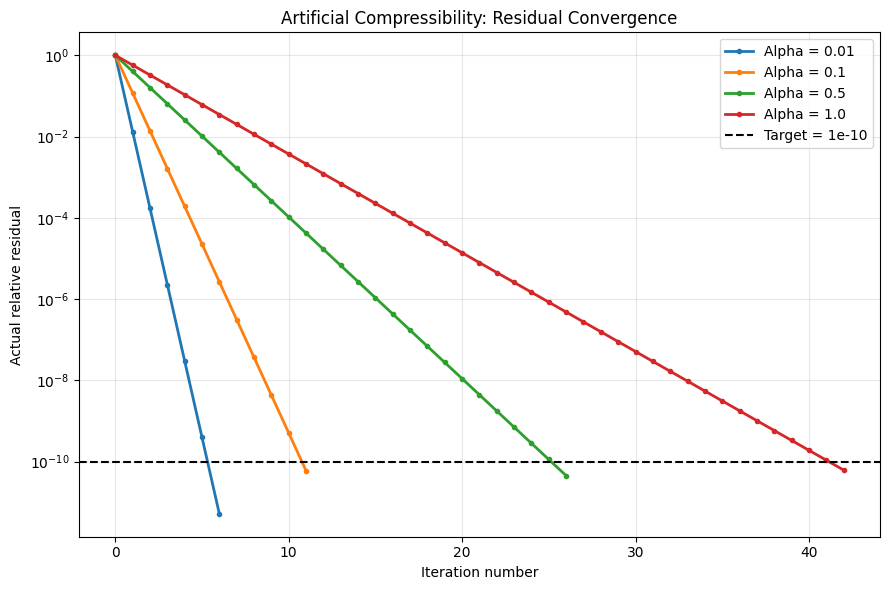

In [17]:
# Step 4: Plot residual convergence for different alpha values

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# Plot the residual history for each alpha value
for alpha_test in alpha_values:

    residuals = alpha_residual_histories[alpha_test]

    iteration_numbers = range(len(residuals))

    plt.semilogy(
        iteration_numbers,
        residuals,
        marker="o",
        markersize=3,
        linewidth=2,
        label=f"Alpha = {alpha_test}"
    )

# Plot the residual target
plt.axhline(
    y=1e-10,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Target = 1e-10"
)

# Add labels and title
plt.xlabel("Iteration number")
plt.ylabel("Actual relative residual")
plt.title("Artificial Compressibility: Residual Convergence")

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()

plt.show()

### Result

I plotted the relative residual histories for four artificial compressibility parameter values.

The graph shows that the residual decreased with each iteration for all four values.

Alpha = 0.01 reached the target in 6 iterations, while alpha = 0.1 required 11 iterations.

Alpha = 0.5 required 26 iterations, and alpha = 1.0 required 42 iterations.

I used a logarithmic scale to compare the convergence behavior.

I observed that smaller alpha values gave faster convergence for my current small matrix example.

This graph helped me understand how the artificial compressibility parameter affects the iterative correction method.

I still need to test this behavior on the actual mixed Darcy system.

## 5. Applying Artificial Compressibility to the Mixed Darcy System

In the previous steps, I studied artificial compressibility using a small matrix example.

Now I will apply the same idea to the mixed Darcy system from my previous notebooks.

I consider the Darcy equations:

$$
\mathbf{q}=-\nabla p
$$

$$
\nabla\cdot\mathbf{q}=f
$$

I will use RT0 elements for flux and P0 elements for pressure on a two-dimensional triangular mesh.

The original saddle-point matrix is:

$$
G=
\begin{bmatrix}
A & -D^T\\
-D & 0
\end{bmatrix}
$$

I will introduce an artificial compressibility parameter of 0.1 and build the modified matrix:

$$
\widetilde{G}_\alpha=
\begin{bmatrix}
A & -D^T\\
-D & -\alpha I
\end{bmatrix}
$$

I will solve both systems directly and check their residuals against the original Darcy system.

This will help me understand how the artificial compressibility term affects the actual finite element problem.


In [18]:
# Step 5: Artificial compressibility for the mixed Darcy system

%pip -q install scikit-fem

from skfem import (
    MeshTri, Basis, ElementTriRT0, ElementTriP0,
    BilinearForm, LinearForm, asm
)
from skfem.helpers import dot, div

from scipy.sparse import bmat, eye
from scipy.sparse.linalg import spsolve

# Create the triangular mesh
mesh_darcy = MeshTri.init_tensor(
    np.linspace(0, 1, 5),
    np.linspace(0, 1, 5)
)

# Create finite element bases
flux_basis_darcy = Basis(
    mesh_darcy, ElementTriRT0(), intorder=2
)

pressure_basis_darcy = Basis(
    mesh_darcy, ElementTriP0(), intorder=2
)

# Flux mass matrix
@BilinearForm
def flux_mass_form(q, v, w):
    return dot(q, v)

# Divergence matrix
@BilinearForm
def divergence_darcy_form(q, r, w):
    return div(q) * r

# Source term
@LinearForm
def darcy_source_form(r, w):
    x = w.x[0]
    y = w.x[1]

    f = 2 * np.pi**2 * np.sin(np.pi*x) * np.sin(np.pi*y)

    return f * r

# Assemble matrices
A_darcy = asm(flux_mass_form, flux_basis_darcy)

D_darcy = asm(
    divergence_darcy_form,
    flux_basis_darcy,
    pressure_basis_darcy
)

F_darcy = asm(darcy_source_form, pressure_basis_darcy)

# Original saddle-point matrix
G_darcy = bmat([
    [A_darcy, -D_darcy.T],
    [-D_darcy, None]
], format="csr")

# Right-hand side
b_darcy = np.concatenate((
    np.zeros(flux_basis_darcy.N),
    -F_darcy
))

# Artificial compressibility parameter
alpha_darcy = 0.1

# Modified pressure block
C_darcy = alpha_darcy * eye(
    pressure_basis_darcy.N,
    format="csr"
)

# Modified saddle-point matrix
G_alpha_darcy = bmat([
    [A_darcy, -D_darcy.T],
    [-D_darcy, -C_darcy]
], format="csr")

# Solve both systems directly
z_original_darcy = spsolve(G_darcy, b_darcy)

z_modified_darcy = spsolve(G_alpha_darcy, b_darcy)

# Calculate relative residuals
b_norm_darcy = np.linalg.norm(b_darcy)

residual_original_darcy = (
    np.linalg.norm(b_darcy - G_darcy @ z_original_darcy)
    / b_norm_darcy
)

residual_modified_darcy = (
    np.linalg.norm(b_darcy - G_alpha_darcy @ z_modified_darcy)
    / b_norm_darcy
)

# Check modified solution in the ORIGINAL system
residual_modified_in_original = (
    np.linalg.norm(b_darcy - G_darcy @ z_modified_darcy)
    / b_norm_darcy
)

# Print results
print("MIXED DARCY SYSTEM")
print("Triangles:", mesh_darcy.nelements)
print("Flux DOFs:", flux_basis_darcy.N)
print("Pressure DOFs:", pressure_basis_darcy.N)
print("Total DOFs:", G_darcy.shape[0])

print("--------------------------------")

print("Original matrix shape:", G_darcy.shape)
print("Modified matrix shape:", G_alpha_darcy.shape)
print("Artificial compressibility parameter:", alpha_darcy)

print("--------------------------------")

print("Original system relative residual:",
      residual_original_darcy)

print("Modified system relative residual:",
      residual_modified_darcy)

print("Modified solution residual in original system:",
      residual_modified_in_original)

print("--------------------------------")

print("Difference between solutions:",
      np.linalg.norm(z_original_darcy - z_modified_darcy))

Note: you may need to restart the kernel to use updated packages.
MIXED DARCY SYSTEM
Triangles: 32
Flux DOFs: 56
Pressure DOFs: 32
Total DOFs: 88
--------------------------------
Original matrix shape: (88, 88)
Modified matrix shape: (88, 88)
Artificial compressibility parameter: 0.1
--------------------------------
Original system relative residual: 7.443571321860165e-16
Modified system relative residual: 5.332651026735715e-16
Modified solution residual in original system: 0.13757985728492336
--------------------------------
Difference between solutions: 0.5985197036326908


### Result

I assembled the mixed Darcy system using RT0 elements for flux and P0 elements for pressure.

The mesh contained 32 triangular elements, with 56 flux degrees of freedom and 32 pressure degrees of freedom.

Both the original and modified matrices had a size of 88 × 88.

I used an artificial compressibility parameter of 0.1.

The original system gave a relative residual of approximately 7.44 × 10⁻¹⁶.

The modified system gave a relative residual of approximately 5.33 × 10⁻¹⁶ when checked against its own equations.

However, when I checked the modified solution against the original Darcy system, the relative residual was approximately 0.137580.

The difference between the two solution vectors was approximately 0.598520.

This experiment showed that the modified system has a different solution from the original Darcy system.

In the next step, I will use the modified matrix to calculate iterative corrections for the original system.

## 6. Solving the Mixed Darcy System Using Artificial Compressibility Iterations

In the previous step, I assembled the original and modified mixed Darcy systems.

I observed that directly solving the modified system did not give the solution of the original system.

Now I will use the modified matrix to calculate iterative corrections.

At each iteration, I will calculate the original system residual:

$$
r_k=b-Gz_k
$$

Then I will solve for the correction:

$$
\widetilde{G}_\alpha\Delta z_k=r_k
$$

I will update the solution using:

$$
z_{k+1}=z_k+\Delta z_k
$$

I will use an artificial compressibility parameter of 0.1 and start with a zero initial guess.

My target actual relative residual is 10⁻¹⁰.

I will compare the final iterative solution with the direct solution of the original Darcy system.


In [19]:
# Step 6: Artificial compressibility iterations for Darcy

from scipy.sparse.linalg import splu

# Set convergence target
darcy_target = 1e-10
darcy_max_iterations = 100

# Start with a zero initial guess
z_iterative_darcy = np.zeros_like(b_darcy)

# Store actual relative residuals
darcy_residual_history = []

# Factorize the modified matrix once
G_alpha_factor = splu(G_alpha_darcy.tocsc())

# Calculate the initial relative residual
initial_residual_darcy = (
    np.linalg.norm(b_darcy - G_darcy @ z_iterative_darcy)
    / b_norm_darcy
)

darcy_residual_history.append(initial_residual_darcy)

print("Iteration 0")
print("Relative residual:", initial_residual_darcy)
print("--------------------------------")

# Perform iterative corrections
for k in range(1, darcy_max_iterations + 1):

    # Calculate residual of the ORIGINAL system
    r_darcy = b_darcy - G_darcy @ z_iterative_darcy

    # Calculate correction using the MODIFIED matrix
    delta_darcy = G_alpha_factor.solve(r_darcy)

    # Update the solution
    z_iterative_darcy = z_iterative_darcy + delta_darcy

    # Calculate actual relative residual
    relative_residual_darcy = (
        np.linalg.norm(b_darcy - G_darcy @ z_iterative_darcy)
        / b_norm_darcy
    )

    darcy_residual_history.append(relative_residual_darcy)

    print("Iteration:", k)
    print("Relative residual:", relative_residual_darcy)

    # Check stopping criterion
    if relative_residual_darcy <= darcy_target:
        break

# Compare with the direct solution
solution_difference_darcy = np.linalg.norm(
    z_iterative_darcy - z_original_darcy
)

relative_solution_difference_darcy = (
    solution_difference_darcy
    / np.linalg.norm(z_original_darcy)
)

print("--------------------------------")
print("FINAL RESULTS")
print("Total iterations:", k)
print("Final relative residual:", relative_residual_darcy)
print("Meets target:", relative_residual_darcy <= darcy_target)
print("Difference from direct solution:",
      solution_difference_darcy)
print("Relative solution difference:",
      relative_solution_difference_darcy)

Iteration 0
Relative residual: 1.0
--------------------------------
Iteration: 1
Relative residual: 0.1375798572849233
Iteration: 2
Relative residual: 0.018928752146647472
Iteration: 3
Relative residual: 0.002604293187832949
Iteration: 4
Relative residual: 0.00035830908626283874
Iteration: 5
Relative residual: 4.929759949972237e-05
Iteration: 6
Relative residual: 6.782561233915858e-06
Iteration: 7
Relative residual: 9.331719467698131e-07
Iteration: 8
Relative residual: 1.2838953486962104e-07
Iteration: 9
Relative residual: 1.7664346563175014e-08
Iteration: 10
Relative residual: 2.430331595914337e-09
Iteration: 11
Relative residual: 3.343747462053835e-10
Iteration: 12
Relative residual: 4.600461025760676e-11
--------------------------------
FINAL RESULTS
Total iterations: 12
Final relative residual: 4.600461025760676e-11
Meets target: True
Difference from direct solution: 2.0014633559428477e-10
Relative solution difference: 4.601327595326559e-11


### Result

I used the artificial compressibility matrix to solve the original mixed Darcy system through iterative corrections.

I started with a zero initial guess and an initial relative residual of 1.0.

After the first iteration, the relative residual decreased to approximately 0.137580.

The residual continued to decrease with each iteration.

After 12 iterations, I obtained a relative residual of approximately 4.60 × 10⁻¹¹, which reached my target of 10⁻¹⁰.

The relative difference between the iterative solution and the direct solution was approximately 4.60 × 10⁻¹¹.

I also reused the LU factorization of the modified matrix instead of calculating a new factorization at every iteration.

This experiment helped me understand how artificial compressibility can be used as an iterative correction method for the original mixed Darcy system.

These results are for my current 88 × 88 system with an artificial compressibility parameter of 0.1.

## 7. Testing Different Artificial Compressibility Parameters on the Mixed Darcy System

In the previous step, I used an artificial compressibility parameter of 0.1 to solve the original mixed Darcy system through iterative corrections.

The method reached my relative residual target in 12 iterations.

Now I will test four different parameter values:

- 0.01
- 0.1
- 0.5
- 1.0

I will use the same 88 × 88 mixed Darcy system and start with a zero initial guess for each test.

For each parameter, I will build the modified matrix and calculate iterative corrections.

I will compare the iteration counts, actual relative residuals, and differences from the direct solution.

My relative residual target will remain 10⁻¹⁰.

I want to understand how the artificial compressibility parameter affects convergence for my current mixed Darcy system.


In [20]:
# Step 7: Test different alpha values on the Darcy system

import pandas as pd
from IPython.display import display

# Artificial compressibility parameters
alpha_darcy_values = [0.01, 0.1, 0.5, 1.0]

# Common stopping criteria
target_darcy_alpha = 1e-10
max_iterations_darcy_alpha = 150

# Store results and residual histories
alpha_darcy_results = []
alpha_darcy_histories = {}

# Test each alpha value
for alpha_value in alpha_darcy_values:

    # Build the modified pressure block
    C_test = alpha_value * eye(
        pressure_basis_darcy.N,
        format="csr"
    )

    # Build the modified saddle-point matrix
    G_alpha_test = bmat([
        [A_darcy, -D_darcy.T],
        [-D_darcy, -C_test]
    ], format="csr")

    # Factorize the modified matrix once
    alpha_factor_test = splu(G_alpha_test.tocsc())

    # Zero initial guess
    z_alpha_test = np.zeros_like(b_darcy)

    # Initial actual relative residual
    initial_residual = (
        np.linalg.norm(b_darcy - G_darcy @ z_alpha_test)
        / b_norm_darcy
    )

    residual_history = [initial_residual]

    # Iterative corrections
    for k in range(1, max_iterations_darcy_alpha + 1):

        # Residual of the original Darcy system
        r_test = b_darcy - G_darcy @ z_alpha_test

        # Correction using the modified matrix
        delta_test = alpha_factor_test.solve(r_test)

        # Update the solution
        z_alpha_test = z_alpha_test + delta_test

        # Calculate actual relative residual
        relative_residual_test = (
            np.linalg.norm(b_darcy - G_darcy @ z_alpha_test)
            / b_norm_darcy
        )

        residual_history.append(relative_residual_test)

        if relative_residual_test <= target_darcy_alpha:
            break

    # Compare with the direct solution
    relative_solution_difference = (
        np.linalg.norm(z_alpha_test - z_original_darcy)
        / np.linalg.norm(z_original_darcy)
    )

    # Store the results
    alpha_darcy_results.append({
        "Alpha": alpha_value,
        "Iterations": k,
        "Relative residual": relative_residual_test,
        "Relative solution difference": relative_solution_difference,
        "Meets target": relative_residual_test <= target_darcy_alpha
    })

    alpha_darcy_histories[alpha_value] = residual_history

# Display the results as a formatted table
alpha_darcy_df = pd.DataFrame(alpha_darcy_results)

display(
    alpha_darcy_df.style
    .format({
        "Alpha": "{:.2f}",
        "Relative residual": "{:.6e}",
        "Relative solution difference": "{:.6e}"
    })
    .hide(axis="index")
)

Alpha,Iterations,Relative residual,Relative solution difference,Meets target
0.01,6,1.499165e-11,1.499449e-11,True
0.10,12,4.600461e-11,4.601328e-11,True
0.50,29,5.837638e-11,5.838740e-11,True
1.00,48,7.170986e-11,7.172333e-11,True


### Result

I tested four artificial compressibility parameter values on the 88 × 88 mixed Darcy system.

With alpha = 0.01, the method reached my residual target in 6 iterations.

With alpha = 0.1, it took 12 iterations. With alpha = 0.5, it took 29 iterations, and with alpha = 1.0, it took 48 iterations.

All four tests reached my actual relative residual target of 10⁻¹⁰.

The relative differences between the iterative solutions and the direct solution were also very small.

I observed that smaller alpha values required fewer iterations for my current Darcy system.

This result is consistent with what I observed in the earlier small matrix example.

I still need to investigate the effect of the parameter on larger meshes and computation time.

## 8. Plotting Residual Convergence for Different Alpha Values

In the previous step, I tested four artificial compressibility parameters on the mixed Darcy system.

Now I want to visualize how the actual relative residual decreases during the iterative correction process.

I will plot the residual histories for alpha values of 0.01, 0.1, 0.5, and 1.0.

The x-axis will show the iteration number, and the y-axis will show the actual relative residual of the original Darcy system.

I will use a logarithmic scale for the residuals.

I will also include a horizontal line showing my residual target of 10⁻¹⁰.

This graph will help me compare the convergence behavior of the four parameter values.


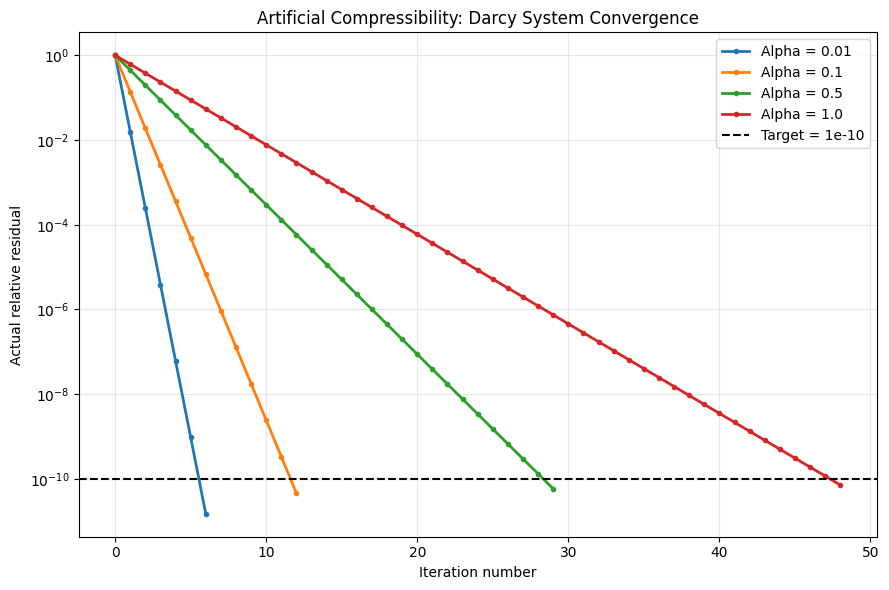

In [21]:
# Step 8: Plot residual convergence for the Darcy system

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# Plot residual history for each alpha value
for alpha_value in alpha_darcy_values:

    residuals = alpha_darcy_histories[alpha_value]

    iteration_numbers = range(len(residuals))

    plt.semilogy(
        iteration_numbers,
        residuals,
        marker="o",
        markersize=3,
        linewidth=2,
        label=f"Alpha = {alpha_value}"
    )

# Plot the residual target
plt.axhline(
    y=1e-10,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Target = 1e-10"
)

# Add labels and title
plt.xlabel("Iteration number")
plt.ylabel("Actual relative residual")
plt.title(
    "Artificial Compressibility: Darcy System Convergence"
)

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()

plt.show()

### Result

I plotted the actual relative residual histories for four artificial compressibility parameter values on the mixed Darcy system.

All four curves started with a relative residual of 1.0 and decreased during the iterative correction process.

With alpha = 0.01, the method reached my residual target in 6 iterations.

Alpha = 0.1 required 12 iterations, alpha = 0.5 required 29 iterations, and alpha = 1.0 required 48 iterations.

I used a logarithmic scale to show how the residual changed during the iterations.

The graph shows that smaller alpha values gave faster convergence for my current 88 × 88 Darcy system.

All four parameter values reached the actual relative residual target of 10⁻¹⁰.

I still need to check how this behavior changes with mesh refinement.

## 9. Testing Artificial Compressibility on Different Mesh Sizes

In the previous steps, I tested different artificial compressibility parameters on an 88 × 88 mixed Darcy system.

Now I want to study how the method performs when I refine the mesh.

I will use three mesh sizes:

- 4 × 4
- 8 × 8
- 16 × 16

For each mesh, I will test four artificial compressibility parameters:

- 0.01
- 0.1
- 0.5
- 1.0

I will assemble the original Darcy system and construct the modified matrix for each parameter.

I will use the iterative correction method with a zero initial guess.

My actual relative residual target will remain 10⁻¹⁰.

I will compare the iteration counts and relative residuals for all 12 tests.

I want to understand how mesh refinement affects convergence for the different parameter values.


In [22]:
# Step 9: Artificial compressibility on different mesh sizes

# Assemble the Darcy system for a given mesh size
def build_darcy_mesh_system(n):

    mesh_test = MeshTri.init_tensor(
        np.linspace(0, 1, n + 1),
        np.linspace(0, 1, n + 1)
    )

    flux_test = Basis(
        mesh_test, ElementTriRT0(), intorder=2
    )

    pressure_test = Basis(
        mesh_test, ElementTriP0(), intorder=2
    )

    A_test = asm(flux_mass_form, flux_test)

    D_test = asm(
        divergence_darcy_form,
        flux_test,
        pressure_test
    )

    F_test = asm(darcy_source_form, pressure_test)

    G_test = bmat([
        [A_test, -D_test.T],
        [-D_test, None]
    ], format="csr")

    b_test = np.concatenate((
        np.zeros(flux_test.N),
        -F_test
    ))

    return A_test, D_test, G_test, b_test, mesh_test.nelements


# Mesh sizes and alpha values
mesh_sizes_darcy = [4, 8, 16]
alpha_values_mesh = [0.01, 0.1, 0.5, 1.0]

# Convergence settings
mesh_target = 1e-10
mesh_max_iterations = 2000

# Store numerical results
mesh_alpha_results = []
mesh_alpha_histories = {}

# Test each mesh
for n in mesh_sizes_darcy:

    A_test, D_test, G_test, b_test, triangles = (
        build_darcy_mesh_system(n)
    )

    b_norm_test = np.linalg.norm(b_test)

    # Test each artificial compressibility parameter
    for alpha_value in alpha_values_mesh:

        # Modified pressure block
        C_test = alpha_value * eye(
            D_test.shape[0],
            format="csr"
        )

        # Modified saddle-point matrix
        G_alpha_test = bmat([
            [A_test, -D_test.T],
            [-D_test, -C_test]
        ], format="csr")

        # Factorize the modified matrix once
        factor_test = splu(G_alpha_test.tocsc())

        # Zero initial guess
        z_test = np.zeros_like(b_test)

        # Store the actual residual history
        residual_history = [1.0]

        # Iterative correction
        for k in range(1, mesh_max_iterations + 1):

            # Residual of the ORIGINAL system
            r_test = b_test - G_test @ z_test

            # Correction using the MODIFIED matrix
            delta_test = factor_test.solve(r_test)

            # Update the solution
            z_test = z_test + delta_test

            # Actual relative residual
            relative_residual = (
                np.linalg.norm(b_test - G_test @ z_test)
                / b_norm_test
            )

            residual_history.append(relative_residual)

            # Check the stopping criterion
            if relative_residual <= mesh_target:
                break

        # Store the numerical results
        mesh_alpha_results.append({
            "Mesh": f"{n} x {n}",
            "Triangles": triangles,
            "DOFs": G_test.shape[0],
            "Alpha": alpha_value,
            "Iterations": k,
            "Relative residual": relative_residual,
            "Meets target": relative_residual <= mesh_target
        })

        # Save residual history for later plotting
        mesh_alpha_histories[(n, alpha_value)] = residual_history

# Convert results to a table
mesh_alpha_df = pd.DataFrame(mesh_alpha_results)

# Display the formatted table
display(
    mesh_alpha_df.style
    .format({
        "Alpha": "{:.2f}",
        "Relative residual": "{:.6e}"
    })
    .hide(axis="index")
)

Mesh,Triangles,DOFs,Alpha,Iterations,Relative residual,Meets target
4 x 4,32,88,0.01,6,1.499165e-11,True
4 x 4,32,88,0.10,12,4.600461e-11,True
4 x 4,32,88,0.50,29,5.837638e-11,True
4 x 4,32,88,1.00,48,7.170986e-11,True
8 x 8,128,336,0.01,9,1.111391e-11,True
8 x 8,128,336,0.10,25,6.954822e-11,True
8 x 8,128,336,0.50,86,8.364160e-11,True
8 x 8,128,336,1.00,160,9.886965e-11,True
16 x 16,512,1312,0.01,15,5.025988e-11,True
16 x 16,512,1312,0.10,71,8.631405e-11,True


### Result

I tested the artificial compressibility method on three different mesh sizes using four parameter values.

The systems contained 88, 336, and 1312 degrees of freedom.

All 12 tests reached my actual relative residual target of 10⁻¹⁰.

I observed that the number of iterations increased when I refined the mesh.

For alpha = 0.01, the iteration counts increased from 6 to 9 and then to 15.

For alpha = 1.0, the iteration counts increased from 48 to 160 and then to 609.

The smallest tested alpha value required the fewest iterations for all three meshes.

These results show that both mesh size and the artificial compressibility parameter affect convergence in my current implementation.

I still need to compare the computation times before deciding which parameter is more efficient.

## 10. Plotting Iteration Counts Against Mesh Size

In the previous step, I tested four artificial compressibility parameters on three different mesh sizes.

Now I want to visualize how the number of iterations changes with mesh refinement.

I will plot the iteration counts for alpha values of 0.01, 0.1, 0.5, and 1.0.

The x-axis will show the mesh size, and the y-axis will show the number of iterations.

I will use a logarithmic scale for the iteration counts because the values range from 6 to 609.

This graph will help me compare the effects of mesh refinement and the artificial compressibility parameter on convergence.


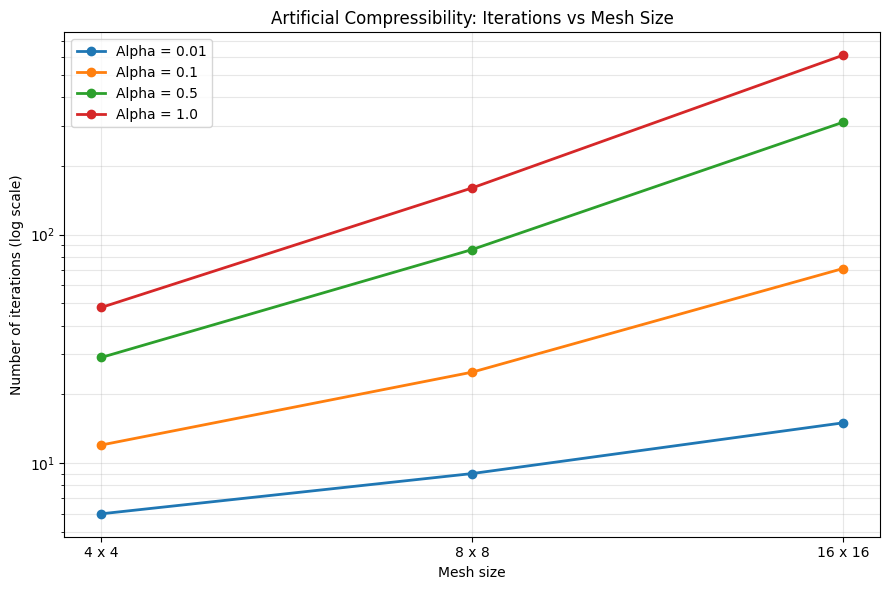

In [23]:
# Step 10: Plot iteration counts against mesh size

import matplotlib.pyplot as plt

# Mesh labels in the correct order
mesh_labels = [
    f"{n} x {n}" for n in mesh_sizes_darcy
]

plt.figure(figsize=(9, 6))

# Plot iteration counts for each alpha value
for alpha_value in alpha_values_mesh:

    # Select results for the current alpha
    data = mesh_alpha_df[
        mesh_alpha_df["Alpha"] == alpha_value
    ]

    # Arrange rows by mesh size
    data = data.set_index("Mesh").loc[mesh_labels]

    plt.plot(
        mesh_labels,
        data["Iterations"],
        marker="o",
        markersize=6,
        linewidth=2,
        label=f"Alpha = {alpha_value}"
    )

# Use logarithmic scale
plt.yscale("log")

# Add labels and title
plt.xlabel("Mesh size")
plt.ylabel("Number of iterations (log scale)")
plt.title(
    "Artificial Compressibility: Iterations vs Mesh Size"
)

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()

plt.show()

### Result

I plotted the iteration counts for four artificial compressibility parameters on three different mesh sizes.

I used a logarithmic scale to display the iteration counts clearly.

The graph shows that the number of iterations increased with mesh refinement for all four parameter values.

For alpha = 0.01, the iteration counts increased from 6 to 9 and then to 15.

For alpha = 1.0, the iteration counts increased from 48 to 160 and then to 609.

I observed that alpha = 0.01 required the fewest iterations for all three tested meshes.

This graph helped me understand how mesh refinement and the artificial compressibility parameter affect convergence in my current implementation.

I still need to compare computation times before drawing conclusions about computational efficiency.

## 11. Comparing Computation Time and Factorization Cost

In the previous steps, I studied how mesh refinement and the artificial compressibility parameter affect iteration counts.

Now I want to compare the computation times.

For each test, I will measure:

- Setup time for building and factorizing the modified matrix.
- Solve time for performing iterative corrections and checking residuals.
- Total computation time.

The total time is:

$$
T_{\mathrm{total}}=T_{\mathrm{setup}}+T_{\mathrm{solve}}
$$

I will use the same three mesh sizes and four alpha values.

I will repeat each configuration five times and calculate the average computation time.

My actual relative residual target will remain 10⁻¹⁰.

I will exclude the original Darcy matrix assembly time.

I want to understand whether a smaller number of iterations also gives a lower total computation time in my current implementation.


In [24]:
# Step 11: Measure artificial compressibility computation time

from time import perf_counter

# Repeat each configuration five times
repetitions = 5

# Store timing results
ac_time_results = []

# Test each mesh size
for n in mesh_sizes_darcy:

    # Assemble the original system outside timing
    A_time, D_time, G_time, b_time, triangles = (
        build_darcy_mesh_system(n)
    )

    b_norm_time = np.linalg.norm(b_time)

    # Test each alpha value
    for alpha_value in alpha_values_mesh:

        setup_times = []
        solve_times = []
        total_times = []
        iteration_counts = []
        residuals = []
        target_checks = []

        # Repeat five times
        for repeat in range(repetitions):

            # Measure setup time
            start_setup = perf_counter()

            C_time = alpha_value * eye(
                D_time.shape[0],
                format="csr"
            )

            G_alpha_time = bmat([
                [A_time, -D_time.T],
                [-D_time, -C_time]
            ], format="csr")

            factor_time = splu(
                G_alpha_time.tocsc()
            )

            setup_time = perf_counter() - start_setup

            # Start with a zero initial guess
            z_time = np.zeros_like(b_time)

            # Measure iterative solve time
            start_solve = perf_counter()

            for k in range(1, mesh_max_iterations + 1):

                # Original system residual
                r_time = b_time - G_time @ z_time

                # Correction using modified matrix
                delta_time = factor_time.solve(r_time)

                # Update solution
                z_time = z_time + delta_time

                # Actual relative residual
                relative_residual_time = (
                    np.linalg.norm(b_time - G_time @ z_time)
                    / b_norm_time
                )

                if relative_residual_time <= mesh_target:
                    break

            solve_time = perf_counter() - start_solve

            # Store computation times in milliseconds
            setup_times.append(setup_time * 1000)
            solve_times.append(solve_time * 1000)

            total_times.append(
                (setup_time + solve_time) * 1000
            )

            iteration_counts.append(k)
            residuals.append(relative_residual_time)

            target_checks.append(
                relative_residual_time <= mesh_target
            )

        # Store average results
        ac_time_results.append({
            "Mesh": f"{n} x {n}",
            "DOFs": G_time.shape[0],
            "Alpha": alpha_value,
            "Iterations": iteration_counts[0],
            "Setup time (ms)": np.mean(setup_times),
            "Solve time (ms)": np.mean(solve_times),
            "Total time (ms)": np.mean(total_times),
            "Max relative residual": max(residuals),
            "Consistent iterations": len(set(iteration_counts)) == 1,
            "All runs passed": all(target_checks)
        })

# Create the results table
ac_time_df = pd.DataFrame(ac_time_results)

# Display formatted results
display(
    ac_time_df.style
    .format({
        "Alpha": "{:.2f}",
        "Setup time (ms)": "{:.4f}",
        "Solve time (ms)": "{:.4f}",
        "Total time (ms)": "{:.4f}",
        "Max relative residual": "{:.6e}"
    })
    .hide(axis="index")
)

Mesh,DOFs,Alpha,Iterations,Setup time (ms),Solve time (ms),Total time (ms),Max relative residual,Consistent iterations,All runs passed
4 x 4,88,0.01,6,0.9437,0.2152,1.1589,1.499165e-11,True,True
4 x 4,88,0.10,12,1.0079,0.4372,1.4452,4.600461e-11,True,True
4 x 4,88,0.50,29,0.9249,0.7719,1.6968,5.837638e-11,True,True
4 x 4,88,1.00,48,0.8455,1.2063,2.0518,7.170986e-11,True,True
8 x 8,336,0.01,9,1.2057,0.4749,1.6806,1.111391e-11,True,True
8 x 8,336,0.10,25,1.1924,1.2318,2.4241,6.954822e-11,True,True
8 x 8,336,0.50,86,1.1875,4.0584,5.2459,8.364160e-11,True,True
8 x 8,336,1.00,160,1.2429,7.5621,8.8050,9.886965e-11,True,True
16 x 16,1312,0.01,15,2.8533,2.2444,5.0977,5.025988e-11,True,True
16 x 16,1312,0.10,71,2.7893,10.1424,12.9317,8.631405e-11,True,True


### Result

I measured the setup time, solve time, and total computation time for different artificial compressibility parameters on three mesh sizes.

I repeated each configuration five times and calculated the average times.

All 60 timed runs reached my relative residual target of 10⁻¹⁰. The iteration counts were also consistent across the repeated runs.

For the 4 × 4 mesh, alpha = 0.01 had the lowest measured total computation time of approximately 1.16 ms.

For the 8 × 8 and 16 × 16 meshes, alpha = 0.01 also gave the lowest measured total times, approximately 1.68 ms and 5.10 ms, respectively.

On the 16 × 16 mesh, alpha = 0.01 required 15 iterations and approximately 5.10 ms. In comparison, alpha = 1.0 required 609 iterations and approximately 86.72 ms.

I observed that both the artificial compressibility parameter and the mesh size affected the computation time.

In this timing run, alpha = 0.01 had both the fewest iterations and the lowest total time on all three meshes. This relationship is not guaranteed for other problems or implementations.

These measurements are based on my current sparse LU implementation. I excluded matrix assembly time, and the computation times may change when I run the notebook again.

## 12. Plotting Computation Time and Factorization Cost

In the previous step, I measured the computation times for different artificial compressibility parameters on three mesh sizes.

Now I want to visualize these results.

First, I will plot the average total computation time against mesh size for the four alpha values.

Then I will use a stacked bar chart to compare the setup time and solve time on the largest mesh.

The total computation time is:

$$
T_{\mathrm{total}}=T_{\mathrm{setup}}+T_{\mathrm{solve}}
$$

I will use the timing results already calculated in Step 11.

These graphs will help me understand how the parameter and mesh size affect computational cost.


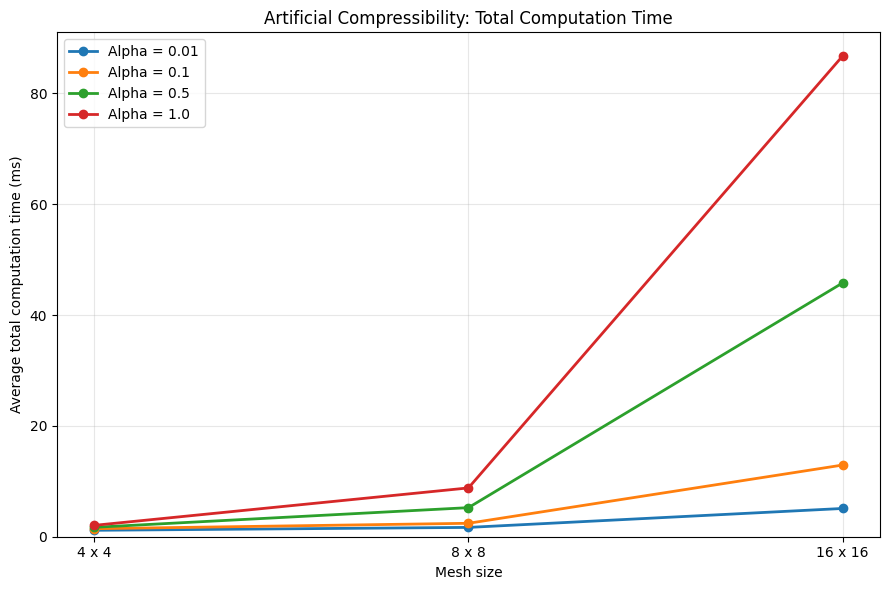

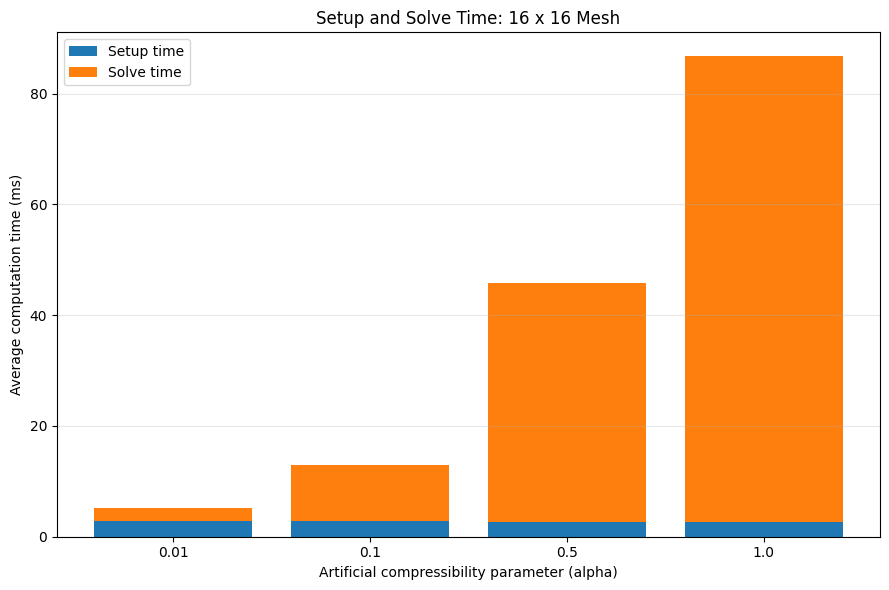

In [26]:
# Step 12: Plot artificial compressibility computation times

import matplotlib.pyplot as plt

# Graph 1: Total computation time vs mesh size

mesh_labels = [
    f"{n} x {n}" for n in mesh_sizes_darcy
]

plt.figure(figsize=(9, 6))

for alpha_value in alpha_values_mesh:

    # Select results for the current alpha
    data = ac_time_df[
        ac_time_df["Alpha"] == alpha_value
    ]

    # Keep mesh sizes in the correct order
    data = data.set_index("Mesh").loc[mesh_labels]

    plt.plot(
        mesh_labels,
        data["Total time (ms)"],
        marker="o",
        linewidth=2,
        label=f"Alpha = {alpha_value}"
    )

plt.xlabel("Mesh size")
plt.ylabel("Average total computation time (ms)")
plt.title("Artificial Compressibility: Total Computation Time")

plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(bottom=0)
plt.tight_layout()

plt.show()


# Graph 2: Setup time and solve time for largest mesh

largest_data = ac_time_df[
    ac_time_df["Mesh"] == "16 x 16"
].sort_values("Alpha")

alpha_labels = [
    str(value) for value in largest_data["Alpha"]
]

plt.figure(figsize=(9, 6))

# Plot setup time
plt.bar(
    alpha_labels,
    largest_data["Setup time (ms)"],
    label="Setup time"
)

# Plot solve time on top of setup time
plt.bar(
    alpha_labels,
    largest_data["Solve time (ms)"],
    bottom=largest_data["Setup time (ms)"],
    label="Solve time"
)

plt.xlabel("Artificial compressibility parameter (alpha)")
plt.ylabel("Average computation time (ms)")
plt.title("Setup and Solve Time: 16 x 16 Mesh")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### Result

I plotted two graphs to compare the computation times of different artificial compressibility parameters.

The first graph shows the average total computation time for three different mesh sizes.

For the 4 × 4 mesh, alpha = 0.01 had the lowest measured total time of approximately 1.16 ms.

For the 8 × 8 and 16 × 16 meshes, alpha = 0.01 also had the lowest measured total times, approximately 1.68 ms and 5.10 ms.

The second graph shows the setup and solve times for the 16 × 16 mesh.

I observed that the setup times were similar for all four parameter values, ranging from approximately 2.64 to 2.85 ms.

However, the solve time increased significantly for larger alpha values.

For alpha = 0.01, the solve time was approximately 2.24 ms. For alpha = 1.0, it was approximately 84.08 ms.

These graphs helped me understand how the artificial compressibility parameter affects computational cost.

The results are based on my current sparse LU implementation. Matrix assembly time was excluded, and the measured times may change when I run the notebook again.

## 13. Final Summary and Limitations

### Final Summary

In this notebook, I studied and implemented the artificial compressibility approach for a mixed Darcy saddle-point system.

I started with a small matrix example to understand how adding an artificial compressibility term changes the original system.

I then used the modified matrix to calculate iterative corrections for the original system.

After understanding the method, I applied it to the two-dimensional mixed Darcy problem using RT0 elements for flux and P0 elements for pressure.

### Work Completed

- Studied the mathematical idea of artificial compressibility.
- Constructed the modified saddle-point matrix.
- Implemented the iterative correction method.
- Compared iterative and direct solutions.
- Tested different artificial compressibility parameters.
- Plotted the residual convergence histories.
- Tested three different mesh sizes.
- Measured setup, solve, and total computation times.
- Plotted and analyzed the timing results.

### Main Findings

I tested four artificial compressibility parameters: 0.01, 0.1, 0.5, and 1.0.

For the mesh refinement study, I used systems with 88, 336, and 1312 degrees of freedom.

All 12 configurations reached my actual relative residual target of 10⁻¹⁰.

I observed that smaller alpha values required fewer iterations for all three tested meshes.

For alpha = 0.01, the iteration counts were 6, 9, and 15.

For alpha = 1.0, the iteration counts were 48, 160, and 609.

I also observed that iteration counts increased with mesh refinement for each fixed alpha value.

### Computation Time

I repeated each timing configuration five times and calculated the average computation time.

All 60 timed runs reached my residual target.

For the 4 × 4 mesh, alpha = 0.01 had the lowest measured total computation time.

For the 8 × 8 and 16 × 16 meshes, alpha = 0.01 had the lowest measured total computation time.

On the largest mesh, alpha = 0.01 required approximately 5.10 ms, while alpha = 1.0 required approximately 86.72 ms.

I found that parameter selection affects both iteration counts and computational costs.

### Limitations

- I studied only a two-dimensional Darcy flow problem with constant permeability.
- I used RT0–P0 finite elements.
- I tested three mesh sizes, with a maximum of 1312 degrees of freedom.
- I tested only four artificial compressibility parameters.
- I used a pressure-block modification of the form −αI.
- I used sparse LU factorization of the modified matrix to calculate the iterative corrections.
- I excluded the original finite element matrix assembly time from the timing comparison.
- I repeated each timing test five times but did not analyze timing variability.
- The measured computation times depend on my implementation and computational environment.

### What I Learned

This notebook helped me understand how a modified saddle-point matrix can be used to solve the original system through iterative corrections.

I also learned that the artificial compressibility parameter affects convergence and that its performance can change with mesh refinement.

The numerical experiments helped me understand why both convergence and computational cost are important when studying iterative methods.

### Future Work

I plan to compare the artificial compressibility results with the MINRES, GMRES, and Schur complement preconditioning experiments from my previous notebooks.

For a fair comparison, I will need to consider the solver settings, actual residual targets, and implementation costs.